# 포켓몬 GO 리뷰 2,500건: 1단계 기술통계 (코딩북 V1.2)

**분석 대상:** A01~A08(8개 평가속성), G(전체 평가), B01(자기보고 행동).

**판정보류 관련 통계는 생성하지 않습니다.** 이 노트북은 모든 U가 이미 해소된 최종 수정 CSV를 사용한다는 전제로 작성하였습니다. 유효한 코드만 허용하며, 잘못된 코드가 있으면 분석을 중단합니다.

**주의:** 별점당 500건인 균등할당 표본이므로 전체 별점 구성비를 실제 플랫폼의 별점 분포로 해석할 수 없습니다. AI 예비라벨 2,000건의 검증 문제는 별도로 검토해야 합니다.

## 1. 환경 및 입력파일

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# 수정 완료한 최종 CSV 파일명에 맞게 변경하세요.
INPUT_FILE = Path("PokemonGO_Merged_2500_V1_2.csv")
OUTPUT_DIR = Path("PokemonGO_Stage1_NoU_Results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ASPECTS = {
    "A01": "게임 콘텐츠·플레이 경험",
    "A02": "과금·게임 내 경제",
    "A03": "보상·확률·성취",
    "A04": "기술적 안정성·이용 편의성",
    "A05": "공간적 접근성·지역 격차",
    "A06": "사회적 상호작용·협력",
    "A07": "게임 운영·서비스 관리",
    "A08": "기기·자원 부담·호환성",
}
CODES = list(ASPECTS) + ["G", "B01"]
SENTIMENT = {"1":"긍정", "0":"중립", "-1":"부정", "9":"미언급"}

def save_table(table, filename):
    table.to_csv(OUTPUT_DIR / filename, index=False, encoding="utf-8-sig")
    return table

if not INPUT_FILE.exists():
    raise FileNotFoundError(f"병합 CSV를 찾을 수 없습니다: {INPUT_FILE.resolve()}")

try:
    df = pd.read_csv(INPUT_FILE, dtype=str, encoding="utf-8-sig")
except UnicodeDecodeError:
    df = pd.read_csv(INPUT_FILE, dtype=str, encoding="cp949")
df.columns = df.columns.str.strip()
print(f"불러온 자료: {INPUT_FILE.name} / {len(df):,}건 / {len(df.columns)}열")

불러온 자료: PokemonGO_Merged_2500_V1_2.csv / 2,500건 / 19열


## 2. 데이터 적합성 점검

U에 대한 빈도표를 작성하지 않습니다. 다만 **코드 오류나 해결되지 않은 값이 존재하면 잘못된 통계 생성을 막기 위해 실행을 중단**합니다.

In [2]:
rating_col = "별점_숫자" if "별점_숫자" in df.columns else "별점"
required = ["ID", rating_col, *CODES]
missing_cols = [c for c in required if c not in df.columns]
if missing_cols:
    raise ValueError(f"필수 열 누락: {missing_cols}")

for c in CODES:
    df[c] = df[c].astype("string").str.strip()

allowed = {c: {"-1", "0", "1", "9"} for c in list(ASPECTS) + ["G"]}
allowed["B01"] = {"0", "1"}
problems = {}
for c in CODES:
    bad = df[c].isna() | ~df[c].isin(allowed[c])
    if bad.any():
        problems[c] = {"건수": int(bad.sum()), "값 예시": df.loc[bad, c].fillna("<결측>").unique()[:7].tolist()}
if problems:
    raise ValueError(f"라벨에 허용되지 않은 값 또는 결측이 있습니다. 원본 CSV를 수정한 후 다시 실행하세요: {problems}")

ratings = pd.to_numeric(df[rating_col], errors="coerce")
if ratings.isna().any() or not ratings.isin([1,2,3,4,5]).all():
    raise ValueError("별점은 1~5의 숫자여야 합니다.")
df["별점_분석"] = ratings.astype(int)
if df["ID"].isna().any() or (df["ID"].astype(str).str.strip() == "").any():
    raise ValueError("ID에 결측값이 있습니다.")
if df["ID"].duplicated().any():
    raise ValueError(f"중복 ID: {df['ID'].duplicated().sum()}건")

checks = pd.DataFrame([
    {"점검 항목":"전체 리뷰 수", "결과":len(df)},
    {"점검 항목":"고유 ID 수", "결과":df['ID'].nunique()},
    {"점검 항목":"별점 유효범위(1~5)", "결과":"정상"},
    {"점검 항목":"A01~A08, G, B01 코드 적합성", "결과":"정상"},
])
display(save_table(checks, "00_데이터_적합성.csv"))

,점검 항목,결과
0,전체 리뷰 수,2500
1,고유 ID 수,2500
2,별점 유효범위(1~5),정상
3,"A01~A08, G, B01 코드 적합성",정상


## 3. 표 1: 별점별 표본 구성

In [3]:
rating_counts = df["별점_분석"].value_counts().reindex(range(1,6), fill_value=0)
t1 = pd.DataFrame({"별점":[f"{i}점" for i in range(1,6)], "빈도(n)":rating_counts.to_numpy()})
t1["백분율(%)"] = (t1["빈도(n)"] / len(df) * 100).round(2)
t1 = pd.concat([t1, pd.DataFrame([{"별점":"전체", "빈도(n)":len(df), "백분율(%)":100.0}])], ignore_index=True)
display(save_table(t1, "01_별점별_표본구성.csv"))

,별점,빈도(n),백분율(%)
0,1점,500,20.0
1,2점,500,20.0
2,3점,500,20.0
3,4점,500,20.0
4,5점,500,20.0
5,전체,2500,100.0


## 4. 표 2: 평가속성별 출현 빈도

출현 = `-1`, `0`, `1`; 미언급 = `9`. 복수 속성 출현이 가능하므로 비율 합계가 100%가 되지 않습니다.

In [4]:
t2_rows = []
for c, name in ASPECTS.items():
    present = df[c].isin(["-1","0","1"])
    t2_rows.append({"코드":c, "평가속성":name, "출현(n)":int(present.sum()), "출현율(%, 전체 2500 대비)":round(present.mean()*100,2), "미언급(n)":int((df[c]=="9").sum())})
t2 = pd.DataFrame(t2_rows)
display(save_table(t2, "02_평가속성별_출현빈도.csv"))

,코드,평가속성,출현(n),"출현율(%, 전체 2500 대비)",미언급(n)
0,A01,게임 콘텐츠·플레이 경험,862,34.48,1638
1,A02,과금·게임 내 경제,254,10.16,2246
2,A03,보상·확률·성취,199,7.96,2301
3,A04,기술적 안정성·이용 편의성,1011,40.44,1489
4,A05,공간적 접근성·지역 격차,87,3.48,2413
5,A06,사회적 상호작용·협력,321,12.84,2179
6,A07,게임 운영·서비스 관리,625,25.00,1875
7,A08,기기·자원 부담·호환성,57,2.28,2443


## 5. 표 3: 평가속성별 감성 구성

긍정·중립·부정은 **해당 평가속성이 출현한 리뷰**를 분모로 비율을 계산합니다.

In [5]:
t3_rows = []
for c, name in ASPECTS.items():
    counts = df[c].value_counts()
    total = int(sum(counts.get(v,0) for v in ["1","0","-1"]))
    row={"코드":c,"평가속성":name,"감성 유효 사례(n)":total}
    for code, label in [("1","긍정"),("0","중립"),("-1","부정")]:
        number = int(counts.get(code,0))
        row[f"{label}(n)"] = number
        row[f"{label}(%)"] = round(number / total*100,2) if total else np.nan
    t3_rows.append(row)
t3 = pd.DataFrame(t3_rows)
display(save_table(t3, "03_평가속성별_감성분포.csv"))

,코드,평가속성,감성 유효 사례(n),긍정(n),긍정(%),중립(n),중립(%),부정(n),부정(%)
0,A01,게임 콘텐츠·플레이 경험,862,381,44.20,0,0.00,481,55.80
1,A02,과금·게임 내 경제,254,68,26.77,27,10.63,159,62.60
2,A03,보상·확률·성취,199,37,18.59,31,15.58,131,65.83
3,A04,기술적 안정성·이용 편의성,1011,80,7.91,14,1.38,917,90.70
4,A05,공간적 접근성·지역 격차,87,11,12.64,6,6.90,70,80.46
5,A06,사회적 상호작용·협력,321,100,31.15,47,14.64,174,54.21
6,A07,게임 운영·서비스 관리,625,89,14.24,62,9.92,474,75.84
7,A08,기기·자원 부담·호환성,57,6,10.53,6,10.53,45,78.95


## 6. 표 4: 별점별 평가속성 출현 건수와 출현율

별점별 출현율 분모는 각 별점의 전체 표본 수입니다.

In [6]:
count_rows=[]
rate_rows=[]
for c,name in ASPECTS.items():
    cn={"코드":c,"평가속성":name}; rt={"코드":c,"평가속성":name}
    for star in range(1,6):
        subset=df.loc[df["별점_분석"]==star,c]
        n_present=int(subset.isin(["-1","0","1"]).sum())
        cn[f"{star}점"]=n_present
        rt[f"{star}점(%)"]=round(n_present/len(subset)*100,2) if len(subset) else np.nan
    count_rows.append(cn);rate_rows.append(rt)
t4_count=pd.DataFrame(count_rows); t4_rate=pd.DataFrame(rate_rows)
display(save_table(t4_count,"04a_별점별_속성출현_건수.csv"))
display(save_table(t4_rate,"04b_별점별_속성출현_비율.csv"))

,코드,평가속성,1점,2점,3점,4점,5점
0,A01,게임 콘텐츠·플레이 경험,161,104,157,195,245
1,A02,과금·게임 내 경제,67,28,47,45,67
2,A03,보상·확률·성취,65,35,34,30,35
3,A04,기술적 안정성·이용 편의성,285,188,217,170,151
4,A05,공간적 접근성·지역 격차,17,11,16,18,25
5,A06,사회적 상호작용·협력,69,36,54,63,99
6,A07,게임 운영·서비스 관리,188,105,128,102,102
7,A08,기기·자원 부담·호환성,21,8,12,10,6


,코드,평가속성,1점(%),2점(%),3점(%),4점(%),5점(%)
0,A01,게임 콘텐츠·플레이 경험,32.2,20.8,31.4,39.0,49.0
1,A02,과금·게임 내 경제,13.4,5.6,9.4,9.0,13.4
2,A03,보상·확률·성취,13.0,7.0,6.8,6.0,7.0
3,A04,기술적 안정성·이용 편의성,57.0,37.6,43.4,34.0,30.2
4,A05,공간적 접근성·지역 격차,3.4,2.2,3.2,3.6,5.0
5,A06,사회적 상호작용·협력,13.8,7.2,10.8,12.6,19.8
6,A07,게임 운영·서비스 관리,37.6,21.0,25.6,20.4,20.4
7,A08,기기·자원 부담·호환성,4.2,1.6,2.4,2.0,1.2


## 7. 표 5: 보조코드 G 및 B01 분포

In [7]:
t5_rows=[]
for value,label in [("1","긍정"),("0","중립"),("-1","부정"),("9","미언급")]:
    nval=int((df["G"]==value).sum())
    t5_rows.append({"변수":"G", "판정":label,"빈도(n)":nval,"전체 대비(%)":round(nval/len(df)*100,2)})
for value,label in [("1","행동 자기보고 있음"),("0","행동 자기보고 없음")]:
    nval=int((df["B01"]==value).sum())
    t5_rows.append({"변수":"B01", "판정":label,"빈도(n)":nval,"전체 대비(%)":round(nval/len(df)*100,2)})
t5=pd.DataFrame(t5_rows)
display(save_table(t5,"05_G_B01_기초분포.csv"))

,변수,판정,빈도(n),전체 대비(%)
0,G,긍정,398,15.92
1,G,중립,9,0.36
2,G,부정,37,1.48
3,G,미언급,2056,82.24
4,B01,행동 자기보고 있음,102,4.08
5,B01,행동 자기보고 없음,2398,95.92


## 8. 그림 1: 평가속성별 출현율

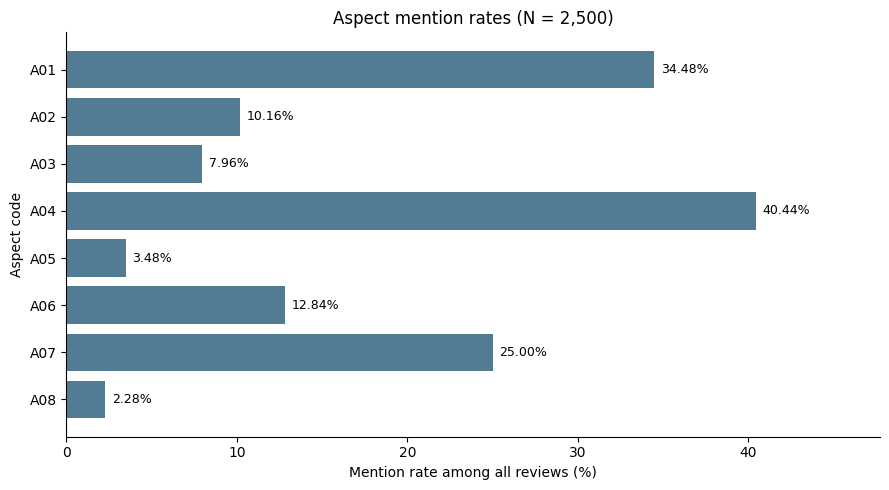

In [8]:
fig,ax=plt.subplots(figsize=(9,5))
plot_data=t2.iloc[::-1]
ax.barh(plot_data["코드"],plot_data["출현율(%, 전체 2500 대비)"],color="#527C94")
ax.set_xlabel("Mention rate among all reviews (%)")
ax.set_ylabel("Aspect code")
ax.set_title("Aspect mention rates (N = 2,500)")
ax.set_xlim(0,max(10,t2["출현율(%, 전체 2500 대비)"].max()*1.18))
for i,v in enumerate(plot_data["출현율(%, 전체 2500 대비)"]):
    ax.text(v+0.4,i,f"{v:.2f}%",va="center",fontsize=9)
ax.spines[["top","right"]].set_visible(False)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"Figure_01_Aspect_Mention.png",dpi=200,bbox_inches="tight")
plt.show()

## 9. 그림 2: 평가속성별 감성 구성(출현 사례 기준)

C:\Users\jspark\AppData\Local\Temp\ipykernel_22848\1252950424.py:14: UserWarning: Glyph 44557 (\N{HANGUL SYLLABLE GEUNG}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\jspark\AppData\Local\Temp\ipykernel_22848\1252950424.py:14: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\jspark\AppData\Local\Temp\ipykernel_22848\1252950424.py:14: UserWarning: Glyph 51473 (\N{HANGUL SYLLABLE JUNG}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\jspark\AppData\Local\Temp\ipykernel_22848\1252950424.py:14: UserWarning: Glyph 47549 (\N{HANGUL SYLLABLE RIB}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\jspark\AppData\Local\Temp\ipykernel_22848\1252950424.py:14: UserWarning: Glyph 48512 (\N{HANGUL SYLLABLE BU}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\jspark\AppData\Local\Temp\ipykernel_22848\1252950424.py:15: UserWarning: Glyph 44557 (\N{HANGUL SYLLABLE GEUNG})

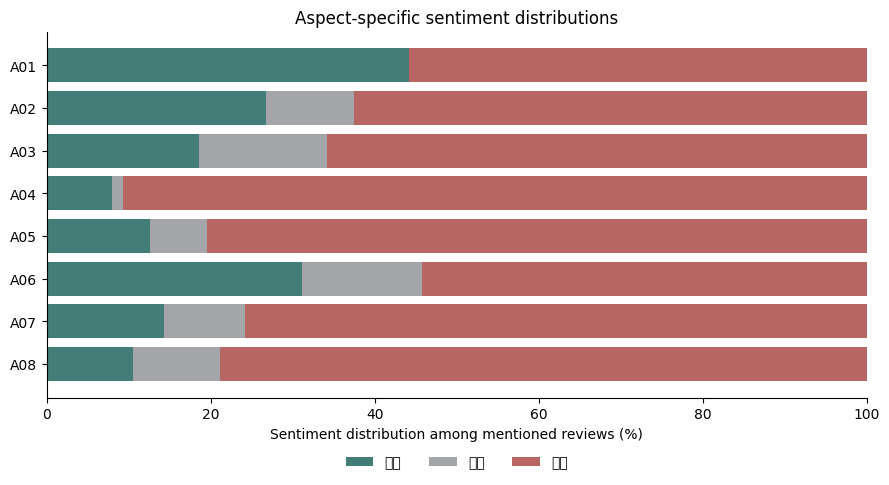

In [9]:
fig,ax=plt.subplots(figsize=(9,5))
colors={"긍정":"#447C77","중립":"#A3A5A8","부정":"#B76663"}
left=np.zeros(len(t3))
for name in ["긍정","중립","부정"]:
    vals=t3[f"{name}(%)"].fillna(0).to_numpy()
    ax.barh(t3["코드"],vals,left=left,label=name,color=colors[name])
    left+=vals
ax.invert_yaxis()
ax.set_xlabel("Sentiment distribution among mentioned reviews (%)")
ax.set_title("Aspect-specific sentiment distributions")
ax.legend(loc="lower center",bbox_to_anchor=(0.5,-0.23),ncol=3,frameon=False)
ax.set_xlim(0,100)
ax.spines[["top","right"]].set_visible(False)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"Figure_02_Aspect_Sentiment.png",dpi=200,bbox_inches="tight")
plt.show()

## 10. 교차검증 및 해석상의 유의사항

In [10]:
assert t1.loc[t1["별점"]=="전체","빈도(n)"].iloc[0] == len(df)
for c in ASPECTS:
    assert t2.loc[t2["코드"]==c,"출현(n)"].iloc[0] == t3.loc[t3["코드"]==c,"감성 유효 사례(n)"].iloc[0]
    assert t4_count.loc[t4_count["코드"]==c,["1점","2점","3점","4점","5점"]].sum(axis=1).iloc[0] == t2.loc[t2["코드"]==c,"출현(n)"].iloc[0]
print("교차검증 완료. CSV와 그림 저장 위치:", OUTPUT_DIR.resolve())
print("주의: 균등할당 표본, 복수 속성 코딩, AI 예비 라벨과 인간 코딩의 출처 차이를 논문에서 명시해야 합니다.")

교차검증 완료. CSV와 그림 저장 위치: D:\vscode_project\포켓몬고\PokemonGO_Stage1_NoU_Results
주의: 균등할당 표본, 복수 속성 코딩, AI 예비 라벨과 인간 코딩의 출처 차이를 논문에서 명시해야 합니다.


In [11]:

# 원자료 15,040건의 별점별 구성
population_counts = {
    1: 2800,
    2: 3160,
    3: 3120,
    4: 3080,
    5: 2880
}

N_population = sum(population_counts.values())

# 별점별 원자료 비중 / 분석 표본 비중
sample_counts = df["별점_분석"].value_counts()

weights = {
    star: (population_counts[star] / N_population)
          / (sample_counts[star] / len(df))
    for star in range(1, 6)
}

df["weight"] = df["별점_분석"].map(weights)

# 가중 출현율 및 감성 구성비
weighted_results = []

for aspect, name in ASPECTS.items():
    present = df[aspect].isin(["-1", "0", "1"])
    total_w = df["weight"].sum()
    present_w = df.loc[present, "weight"].sum()

    row = {
        "코드": aspect,
        "평가속성": name,
        "기존 출현율(%)": round(present.mean() * 100, 2),
        "가중 출현율(%)": round(present_w / total_w * 100, 2)
    }

    for code, label in [
        ("1", "긍정"),
        ("0", "중립"),
        ("-1", "부정")
    ]:
        sentiment_w = df.loc[
            df[aspect] == code, "weight"
        ].sum()

        row[f"가중 {label}(%)"] = (
            round(sentiment_w / present_w * 100, 2)
            if present_w > 0 else np.nan
        )

    weighted_results.append(row)

weighted_table = pd.DataFrame(weighted_results)

display(weighted_table)

weighted_table.to_csv(
    OUTPUT_DIR / "06_가중_출현율_감성분포.csv",
    index=False,
    encoding="utf-8-sig"
)


,코드,평가속성,기존 출현율(%),가중 출현율(%),가중 긍정(%),가중 중립(%),가중 부정(%)
0,A01,게임 콘텐츠·플레이 경험,34.48,34.25,44.09,0.00,55.91
1,A02,과금·게임 내 경제,10.16,10.03,26.78,10.64,62.59
2,A03,보상·확률·성취,7.96,7.87,18.80,15.54,65.66
3,A04,기술적 안정성·이용 편의성,40.44,40.26,7.96,1.43,90.61
4,A05,공간적 접근성·지역 격차,3.48,3.45,12.47,6.92,80.61
5,A06,사회적 상호작용·협력,12.84,12.69,31.16,14.62,54.22
6,A07,게임 운영·서비스 관리,25.00,24.81,14.18,9.82,76.00
7,A08,기기·자원 부담·호환성,2.28,2.26,10.71,10.87,78.42
